# A Two-Class MLP from Scratch

The classroom demo from Lecture 11, as a notebook. Everything here is NumPy:
a one-hidden-layer network with tanh units, its gradient derived by
backpropagation, and gradient descent on a two-dimensional classification
problem small enough to draw. Because the input has two coordinates we can
draw the decision rule after every update, draw each hidden unit as a
function on the plane, and watch what changes when we change the width, the
learning rate, or the random seed.

The question the notebook answers is the one on the slide: which changes
alter the **function class**, and which alter only the **training path**
within that class? We will:

1. show that logistic regression, whose boundary is a line, cannot separate
   two interleaved half-circles;
2. write the forward pass of a tanh network and check that removing the
   activation collapses it to logistic regression;
3. derive the gradient by backpropagation and check it against finite
   differences;
4. train by full-batch gradient descent and watch the boundary bend;
5. read the hidden units as learned features;
6. vary the width, the learning rate, and the seed separately, and sort each
   change into "function class" or "training path";
7. verify the hand-written gradient and the training loop with PyTorch.

Every run uses the fixed seed `SEED = 26512`, so the numbers quoted in the
text match the printed outputs.

## Data: two interleaved half-circles

The next cell draws 180 points from each of two noisy half-circles (noise
standard deviation 0.10) and defines a $200\times200$ grid on which every
later cell evaluates its predicted probability. The helper `draw` shades
the grid by predicted class and traces the 0.5 contour in green. Look at
the scatter: the upper moon (blue, class 0) wraps over the left tip of the
lower moon (red, class 1), and vice versa.

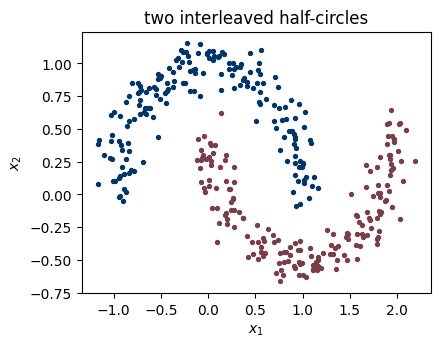

observations: (360, 2)  class balance: 0.5


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 26512
BLUE, RED, GREEN = '#00356B', '#7A3E47', '#5B7864'

def two_moons(n=180, seed=SEED):
    rng = np.random.default_rng(seed)
    angle = rng.uniform(0, np.pi, n)
    upper = np.column_stack([np.cos(angle), np.sin(angle)]) + rng.normal(0, 0.10, (n, 2))
    lower = np.column_stack([1 - np.cos(angle), 0.5 - np.sin(angle)]) + rng.normal(0, 0.10, (n, 2))
    return np.vstack([upper, lower]), np.r_[np.zeros(n), np.ones(n)]

X, y = two_moons()
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1.2, 1.6, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])

def draw(ax, probability_on_grid=None, title=''):
    """Scatter the data; optionally shade the grid by predicted class."""
    if probability_on_grid is not None:
        prob = probability_on_grid.reshape(xx.shape)
        ax.contourf(xx, yy, prob, levels=[0, 0.5, 1], colors=['#DCE8F2', '#F4DEE0'])
        ax.contour(xx, yy, prob, levels=[0.5], colors=[GREEN], linewidths=1.5)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=8, color=BLUE)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=8, color=RED)
    ax.set(title=title, xlabel='$x_1$', ylabel='$x_2$')

fig, ax = plt.subplots(figsize=(4.5, 3.4))
draw(ax, title='two interleaved half-circles')
plt.show()
assert X.shape == (360, 2) and y.mean() == 0.5
print('observations:', X.shape, ' class balance:', y.mean())

There are $n=360$ observations in $\mathbb R^2$, exactly half in each
class, so a constant predictor scores 0.5 accuracy. That is the floor every
later accuracy should be compared with.

## 1. A linear classifier runs out of room

Logistic regression (Lecture 8) fits $p(x)=\sigma(w^\top x+b)$ by gradient
descent on the cross-entropy. Its decision boundary is a line, and no line
separates two interleaved half-circles. The next cell runs 2000 full-batch
updates with step size 1 and shades the fitted rule. Look at where the
misclassified points sit relative to the line.

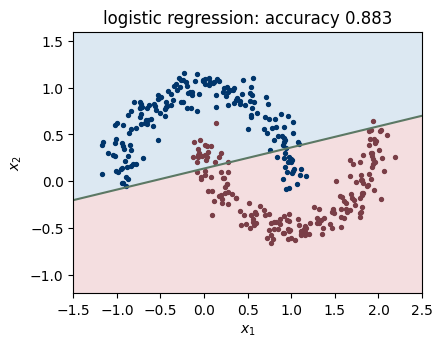

training accuracy 0.883, cross-entropy 0.257, misclassified 42 of 360


In [2]:
def sigmoid(v):
    return 1 / (1 + np.exp(-np.clip(v, -30, 30)))

def cross_entropy(p, y):
    return -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))

w, b = np.zeros(2), 0.0
for step in range(2000):
    p = sigmoid(X @ w + b)
    gradient = (p - y) / len(y)              # dL/d(score), one entry per observation
    w -= 1.0 * (X.T @ gradient)
    b -= 1.0 * gradient.sum()
linear_accuracy = np.mean((sigmoid(X @ w + b) > 0.5) == y)
linear_loss = cross_entropy(sigmoid(X @ w + b), y)
fig, ax = plt.subplots(figsize=(4.5, 3.4))
draw(ax, sigmoid(grid @ w + b), title=f'logistic regression: accuracy {linear_accuracy:.3f}')
plt.show()
assert 0.8 < linear_accuracy < 0.95
print(f'training accuracy {linear_accuracy:.3f}, cross-entropy {linear_loss:.3f}, '
      f'misclassified {int(round((1 - linear_accuracy) * len(y)))} of {len(y)}')

The line reaches training accuracy 0.883 (42 of 360 points wrong) with
cross-entropy 0.257. The errors are concentrated at the two tips, where
each moon reaches into the other's hollow: any line that tilts to catch one
tip gives up points elsewhere. More updates cannot fix this, because the
limitation is in the model. We need a function class with curved
boundaries.

## 2. The model: one hidden layer of tanh units

With hidden width $m$, the network computes
$$z=W_1x+b_1\in\mathbb R^m,\qquad h=\tanh(z),\qquad
s=w_2^\top h+b_2,\qquad p=\sigma(s),$$
with $W_1\in\mathbb R^{m\times2}$, matching the slides' $h(x)=\sigma(W_1x+b_1)$
and the layer convention $z=Wh+b$. **Code convention:** the array `W1`
stores the transpose $W_1^\top$, of shape $(2,m)$, so that the $(n,2)$ data
matrix times `W1` gives the $(n,m)$ matrix `Z` whose row $i$ is $z_i^\top$.
The activation is what makes depth count: with the identity in place of
$\tanh$, the two affine maps compose into a single affine map
$x\mapsto (w_2^\top W_1)x+(w_2^\top b_1+b_2)$, and the model is logistic
regression again.

The next cell defines the initialization (weights $N(0,0.65^2)$ in the first
layer, $N(0,0.5^2)$ in the output layer, zero biases) and the forward pass,
then checks the collapse identity numerically. Look for an `assert` that
passes and the collapsed weight vector $W_1^\top w_2$ (code: `W1 @ w2`).

In [3]:
def initialize(width, seed=SEED):
    local = np.random.default_rng(seed + width)
    return {'W1': local.normal(0, 0.65, (2, width)), 'b1': np.zeros(width),
            'w2': local.normal(0, 0.50, (width, 1)), 'b2': np.zeros(1)}

def forward(params, points, activation=np.tanh):
    Z = points @ params['W1'] + params['b1']      # row i is (W_1 x_i + b_1)^T
    H = activation(Z)
    S = (H @ params['w2'] + params['b2']).ravel()
    return Z, H, sigmoid(S)

params = initialize(width=8)
_, H, p = forward(params, X)
print('hidden values:', H.shape, ' probabilities:', p.shape)

# Without the activation the network collapses to one affine map.
_, _, p_identity = forward(params, X, activation=lambda z: z)
w_collapsed = params['W1'] @ params['w2']
b_collapsed = params['b1'] @ params['w2'] + params['b2']
assert np.allclose(p_identity, sigmoid((X @ w_collapsed + b_collapsed).ravel()))
print('identity activation = logistic regression with w =', np.round(w_collapsed.ravel(), 3))

hidden values: (360, 8)  probabilities: (360,)
identity activation = logistic regression with w = [ 0.345 -0.059]


With width 8 the hidden matrix has shape $(360,8)$ and the output is one
probability per observation. The assert confirms that the identity-activation
network computes exactly $\sigma(x^\top w+b)$ with $w=W_1^\top w_2=(0.345,-0.059)$
at this initialization. Eight hidden units with no nonlinearity buy nothing
beyond the single line of Section 1.

## 3. The gradient by backpropagation

The loss is the mean cross-entropy $L=-\frac1n\sum_i\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]$.
Writing $\overline v=\partial L/\partial v$ and stacking observations as
rows (so `Z`, `H`, $\overline Z$, $\overline H$ are $n\times m$), the local
rules from the lecture give, in reverse order,
$$\overline s=\tfrac1n(p-y),\qquad
\overline w_2=H^\top\overline s,\qquad \overline b_2=\mathbf 1^\top\overline s,\qquad
\overline H=\overline s\,w_2^\top,$$
$$\overline Z=\overline H\odot(1-H^2),\qquad
\overline{W_1^\top}=X^\top\overline Z,\qquad \overline b_1=\mathbf 1^\top\overline Z,$$
using $\tanh'(z)=1-\tanh^2(z)$. The slide rule $\overline W=\overline z\,x^\top$,
summed over observations, gives $\overline W_1=\overline Z^\top X$; its
transpose $X^\top\overline Z$ has the shape of the stored array `W1`.

Before trusting these formulas the next cell compares five coordinates with
centered finite differences $[L(\theta+\epsilon e_k)-L(\theta-\epsilon e_k)]/(2\epsilon)$,
$\epsilon=10^{-6}$. For each parameter block it picks the coordinate with the
largest gradient magnitude, because a relative error is unreliable when the
gradient itself is near zero. The pass criterion combines both scales:
$|\text{backprop}-\text{numeric}|\le10^{-9}+10^{-6}|\text{numeric}|$.

In [4]:
def loss_and_gradients(params, X, y):
    Z, H, p = forward(params, X)
    s_bar = ((p - y) / len(y))[:, None]
    H_bar = s_bar @ params['w2'].T
    Z_bar = H_bar * (1 - H ** 2)
    gradients = {'w2': H.T @ s_bar, 'b2': s_bar.sum(0),
                 'W1': X.T @ Z_bar, 'b1': Z_bar.sum(0)}
    return cross_entropy(p, y), gradients

loss, gradients = loss_and_gradients(params, X, y)
for name in params:
    assert gradients[name].shape == params[name].shape

# Largest-magnitude coordinate in each block, plus a second W1 entry.
largest = {name: np.unravel_index(np.abs(g).argmax(), g.shape) for name, g in gradients.items()}
checks = [('W1', largest['W1']), ('W1', (1, 5)), ('b1', largest['b1']),
          ('w2', largest['w2']), ('b2', largest['b2'])]
rows = []
epsilon = 1e-6
for name, index in checks:
    plus = {k: v.copy() for k, v in params.items()}; plus[name][index] += epsilon
    minus = {k: v.copy() for k, v in params.items()}; minus[name][index] -= epsilon
    numeric = (loss_and_gradients(plus, X, y)[0] - loss_and_gradients(minus, X, y)[0]) / (2 * epsilon)
    error = abs(gradients[name][index] - numeric)
    rows.append({'coordinate': f'{name}{tuple(int(i) for i in index)}', 'backprop': gradients[name][index],
                 'finite difference': numeric, 'absolute error': error,
                 'relative error': error / abs(numeric)})
display(pd.DataFrame(rows))
assert all(r['absolute error'] <= 1e-9 + 1e-6 * abs(r['finite difference']) for r in rows)

,coordinate,backprop,finite difference,absolute error,relative error
0,"W1(1, 1)",0.088810,0.088810,2.680495e-11,3.018242e-10
1,"W1(1, 5)",-0.007986,-0.007986,4.548639e-11,5.695805e-09
2,"b1(1,)",0.037001,0.037001,5.682103e-11,1.535645e-09
3,"w2(7, 0)",-0.188860,-0.188860,2.954781e-11,1.564531e-10
4,"b2(0,)",0.028500,0.028500,3.286627e-11,1.153210e-09


Every block's gradient has the shape of its parameter, and all five
coordinates agree with the finite differences to absolute error below
$6\times10^{-11}$ and relative error below $6\times10^{-9}$. The checked
gradients range in size from $0.008$ (`W1(1, 5)`) to $0.189$ (`w2(7, 0)`), so
the relative errors are measured against gradients well away from zero. The
remaining discrepancy is the $O(\epsilon^2)$ truncation and rounding error of
the finite difference itself.

## 4. Watch the boundary move

Full-batch gradient descent, $\theta\leftarrow\theta-\eta\nabla L(\theta)$,
with all 360 observations in every update and $\eta=3$. The function `train`
returns the parameters at the requested update counts so that we can draw
the decision rule at four moments: updates 0, 20, 100, and 800. Watch the
panel titles for the accuracy and the second plot for the loss on a log
scale.

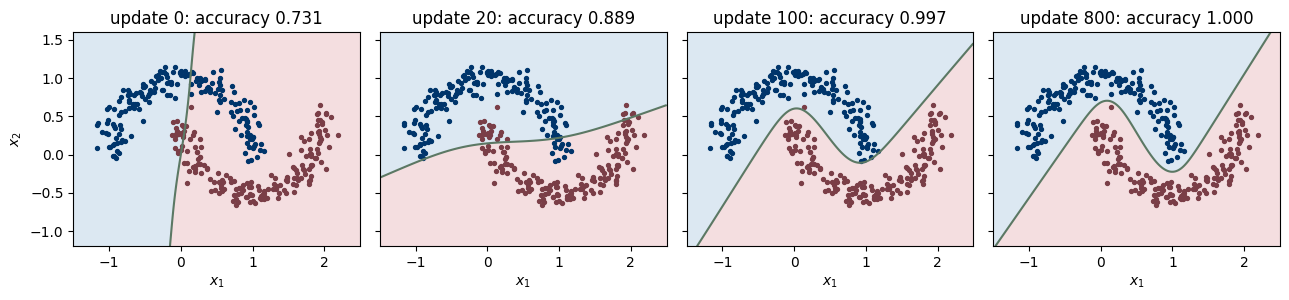

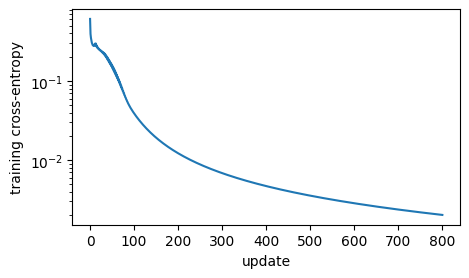

update   0: loss 0.6101, accuracy 0.731
update  20: loss 0.2516, accuracy 0.889
update 100: loss 0.0390, accuracy 0.997
update 800: loss 0.0020, accuracy 1.000


In [5]:
def train(width=8, rate=3.0, steps=800, seed=SEED, snapshots=()):
    params = initialize(width, seed)
    losses, saved = [], {}
    for t in range(steps + 1):
        if t in snapshots:
            saved[t] = {k: v.copy() for k, v in params.items()}
        loss, gradients = loss_and_gradients(params, X, y)
        losses.append(loss)
        if t == steps:
            break
        for name in params:
            params[name] -= rate * gradients[name]
    return params, np.array(losses), saved

def accuracy_of(params):
    return np.mean((forward(params, X)[2] > 0.5) == y)

params, losses, saved = train(snapshots=(0, 20, 100, 800))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)
for ax, (t, snapshot) in zip(axes, saved.items()):
    draw(ax, forward(snapshot, grid)[2], title=f'update {t}: accuracy {accuracy_of(snapshot):.3f}')
    ax.set_ylabel('$x_2$' if t == 0 else '')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(losses)
ax.set(xlabel='update', ylabel='training cross-entropy', yscale='log')
plt.show()
for t, snapshot in saved.items():
    print(f'update {t:3d}: loss {losses[t]:.4f}, accuracy {accuracy_of(snapshot):.3f}')
assert accuracy_of(params) == 1.0

At update 0 the random initialization draws a nearly vertical boundary and
already scores 0.731, with loss 0.610. By update 20 the boundary has turned
to the direction logistic regression found and accuracy is 0.889 (loss
0.252), slightly above the line's 0.883. By update 100 it has bent into an
S around the tip of the lower moon, misclassifying one point (0.997, loss
0.039), and at update 800 every point is correct (1.000, loss 0.0020). The
loss curve keeps falling after accuracy saturates: the boundary barely
moves, while the predicted probabilities are pushed toward 0 and 1. The
small sawtooth in the loss during the first 60 or so updates is the first
sign that $\eta=3$ is close to the largest stable step; Section 7 returns to
this.

## 5. Hidden units are learned features

Hidden unit $j$ computes $h_j(x)=\tanh(w_{1j}^\top x+b_{1j})$, where
$w_{1j}^\top$ is row $j$ of $W_1$ (column `j` of the array `W1`): a smooth
step across a line in the plane. Its contribution to the output score is
$w_{2j}h_j(x)$, and the network adds all eight contributions:
$$s(x)=\sum_{j=1}^{8}w_{2j}h_j(x)+b_2.$$
Each panel shades one hidden unit's value. The green curve is the **same
final decision boundary** overlaid on every panel; it is not that unit's
own boundary. The printed output weight shows whether the unit's pattern
adds to or subtracts from the score. The table below the figure measures
how much each unit moves the score across the data: the range of
$w_{2j}h_j(x_i)$ over the 360 observations.

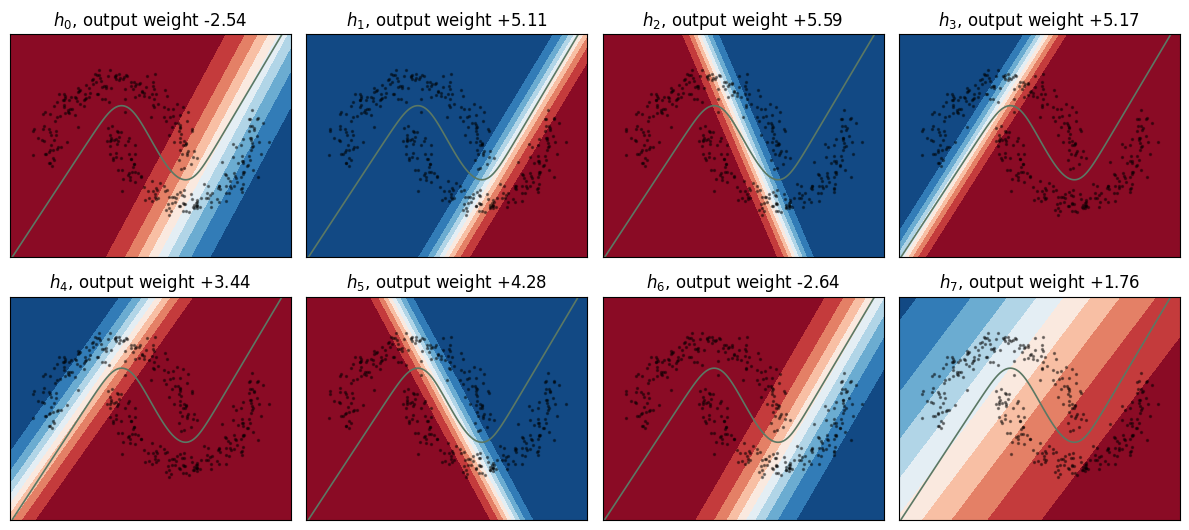

,output weight,contribution range on data
unit,,
0,-2.54,4.65
1,5.11,10.16
2,5.59,11.18
3,5.17,10.33
4,3.44,6.67
5,4.28,8.55
6,-2.64,4.89
7,1.76,2.44


In [6]:
def draw_hidden_units(params, axes, boundary=True, compact=False):
    _, H_grid, p_grid = forward(params, grid)
    for j, ax in enumerate(axes):
        ax.contourf(xx, yy, H_grid[:, j].reshape(xx.shape), levels=np.linspace(-1, 1, 11), cmap='RdBu_r')
        if boundary:
            ax.contour(xx, yy, p_grid.reshape(xx.shape), levels=[0.5], colors=[GREEN], linewidths=1.2)
        ax.scatter(X[:, 0], X[:, 1], s=2, color='black', alpha=0.4)
        label = f'$h_{j}$: {params["w2"][j, 0]:+.2f}' if compact else f'$h_{j}$, output weight {params["w2"][j, 0]:+.2f}'
        ax.set(title=label, xticks=[], yticks=[])

fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
draw_hidden_units(params, axes.ravel())
plt.tight_layout(); plt.show()

_, H_data, _ = forward(params, X)
contribution = H_data * params['w2'].ravel()
units = pd.DataFrame({'output weight': params['w2'].ravel(),
                      'contribution range on data': np.ptp(contribution, axis=0)})
units.index.name = 'unit'
display(units.round(2))

After training, seven of the eight hidden units are sharp steps across a
line, and the output weights are large: units 1, 2, and 3 carry weights $+5.11$, $+5.59$,
$+5.17$ and each move the score by more than 10 across the data, while unit 7
is a soft ramp with weight $+1.76$ and range 2.44. The steps divide the work.
The left arm of the boundary runs along the steps of $h_3$ and $h_4$; the
right arm runs along the parallel steps of $h_0$, $h_1$, and $h_6$; and $h_2$
and $h_5$, whose steps slope the other way, carve the dip that wraps under
the upper moon's right tip. No single unit traces the curve. Gradient
descent learned both where each step lies and how much it contributes.

## 6. Width changes the function class

Train the same way ($\eta=3$, 800 updates) at widths 1, 2, 4, 8, and 32. A
width-one network is $\sigma(w_2\tanh(w_1^\top x+b_1)+b_2)$, a monotone
function of the linear score $w_1^\top x+b_1$, so any decision boundary it
has is a line. With two or more units, sums of tanh features can produce
curved boundaries; there is no general "one bend per unit" rule. A network of
width $m$ has $2m+m+m+1=4m+1$ parameters. Look at the shape of each green
boundary and at the accuracy column of the table.

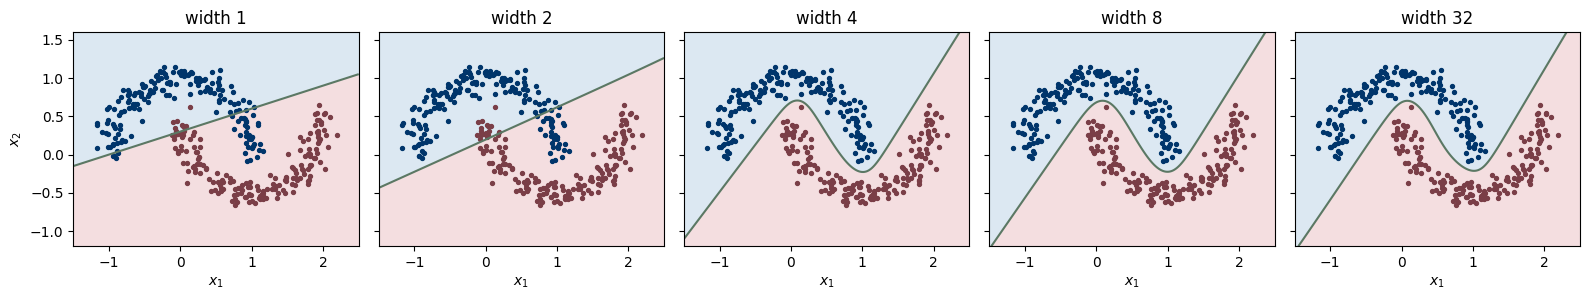

,parameters,final loss,training accuracy
width,,,
1,5,0.302,0.875
2,9,0.230,0.856
4,17,0.003,1.000
8,33,0.002,1.000
32,129,0.003,1.000


In [7]:
widths = [1, 2, 4, 8, 32]
fig, axes = plt.subplots(1, len(widths), figsize=(16, 3.1), sharey=True)
rows = []
for ax, width in zip(axes, widths):
    fitted, losses_w, _ = train(width=width)
    rows.append({'width': width, 'parameters': 4 * width + 1,
                 'final loss': losses_w[-1], 'training accuracy': accuracy_of(fitted)})
    draw(ax, forward(fitted, grid)[2], title=f'width {width}')
    ax.set_ylabel('$x_2$' if width == 1 else '')
plt.tight_layout(); plt.show()
width_table = pd.DataFrame(rows).set_index('width')
display(width_table.round(3))
assert (width_table.loc[[4, 8, 32], 'training accuracy'] == 1.0).all()
assert (width_table.loc[[1, 2], 'training accuracy'] < 0.9).all()

The table splits cleanly. Widths 1 and 2 end with straight boundaries,
final losses 0.302 and 0.230, and training accuracies 0.875 and 0.856, both
slightly below the 0.883 of logistic regression. For width 1 the straight
line is forced by the function class. Width 2 could in principle bend, but
this run found a nearly linear rule. From width 4 on, all three runs reach
accuracy 1.000 with final loss at most 0.003 and essentially the same
S-shaped boundary. Going from 17 to 129 parameters buys nothing further on
this data: once the class contains a separating curve, the extra width only
offers more ways to represent it.

## 7. The learning rate changes the training path

Hold the width at eight and the initialization fixed; change only $\eta$,
over four rates spanning more than two orders of magnitude, for 400 updates
each. Every run starts from the same parameters, with the same loss 0.610.
The table records the final loss and accuracy, the largest loss during the
first 100 updates, the largest loss after update 100, and how many of the 400
updates *increased* the loss. Predict before running: which rate is too slow,
and which overshoots?

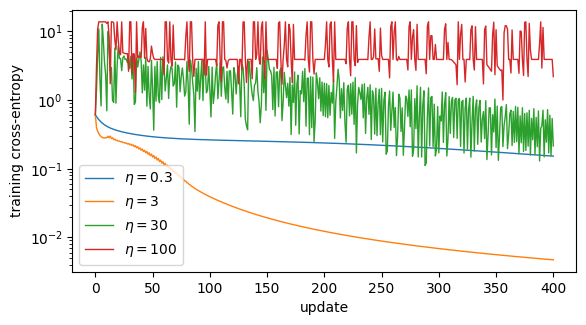

,final loss,training accuracy,"largest loss, updates 0-100",largest loss after update 100,updates that raised the loss
learning rate,,,,,
0.3,0.152,0.947,0.610,0.262,0
3.0,0.005,1.000,0.610,0.038,34
30.0,0.214,0.931,12.765,5.215,211
100.0,2.193,0.858,13.771,13.771,119


In [8]:
rates = [0.3, 3.0, 30.0, 100.0]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
rows = []
for rate in rates:
    fitted, losses_r, _ = train(rate=rate, steps=400)
    ax.plot(losses_r, lw=1, label=f'$\\eta={rate:g}$')
    rows.append({'learning rate': rate, 'final loss': losses_r[-1],
                 'training accuracy': accuracy_of(fitted),
                 'largest loss, updates 0-100': losses_r[:101].max(),
                 'largest loss after update 100': losses_r[101:].max(),
                 'updates that raised the loss': int(np.sum(np.diff(losses_r) > 0))})
ax.set(xlabel='update', ylabel='training cross-entropy', yscale='log')
ax.legend()
plt.show()
rate_table = pd.DataFrame(rows).set_index('learning rate')
display(rate_table.round(3))
assert rate_table.loc[0.3, 'updates that raised the loss'] == 0
assert rate_table.loc[3.0, 'training accuracy'] == 1.0
assert rate_table.loc[30.0, 'largest loss, updates 0-100'] > 10 * rate_table.loc[30.0, 'final loss']
assert rate_table.loc[100.0, 'final loss'] > linear_loss

Each rate maps to a distinct behavior.

- **$\eta=0.3$ is slow.** The loss never increases (0 of 400 updates raise
  it), and it is still falling at update 400, ending at 0.152 with accuracy
  0.947. The run is stable and unfinished.
- **$\eta=3$ is near the edge of stability.** 34 updates raise the loss, all
  during the early sawtooth visible in the plot; the loss never exceeds its
  starting value 0.610, and after update 100 it falls steadily to 0.005 with
  accuracy 1.000. This is the fastest of the four.
- **$\eta=30$ spikes.** Within the first 100 updates the loss jumps from
  0.610 to 12.765, about 21 times its starting value. It keeps bouncing: 211
  of 400 updates raise the loss, the largest loss after update 100 is 5.215,
  and the run ends at loss 0.214 and accuracy 0.931. Where it ends depends
  on where the last of many bouncing steps happened to land.
- **$\eta=100$ fails.** The loss jumps to 13.771 within five updates and
  returns to that level after update 100. It ends at loss 2.193 with accuracy
  0.858, a worse loss (and lower accuracy) than the straight line's 0.257 and
  0.883.

All four runs use the same width-8 function class, the one that reached
accuracy 1.000 in Section 6. The learning rate changed only which point of
that class the optimizer visited, and whether it settled anywhere.

## 8. The seed changes the representation

Two runs with the same width, rate, and data, differing only in the random
initialization (`SEED` and `SEED + 7`). Each row of the figure shows one
run's eight hidden units with that run's final boundary in green. Compare
the rows: are the steps in the same places, with the same output weights?
Each panel title gives that unit's output weight, and the printout lists
each run's final loss, accuracy, and output weights sorted by size.

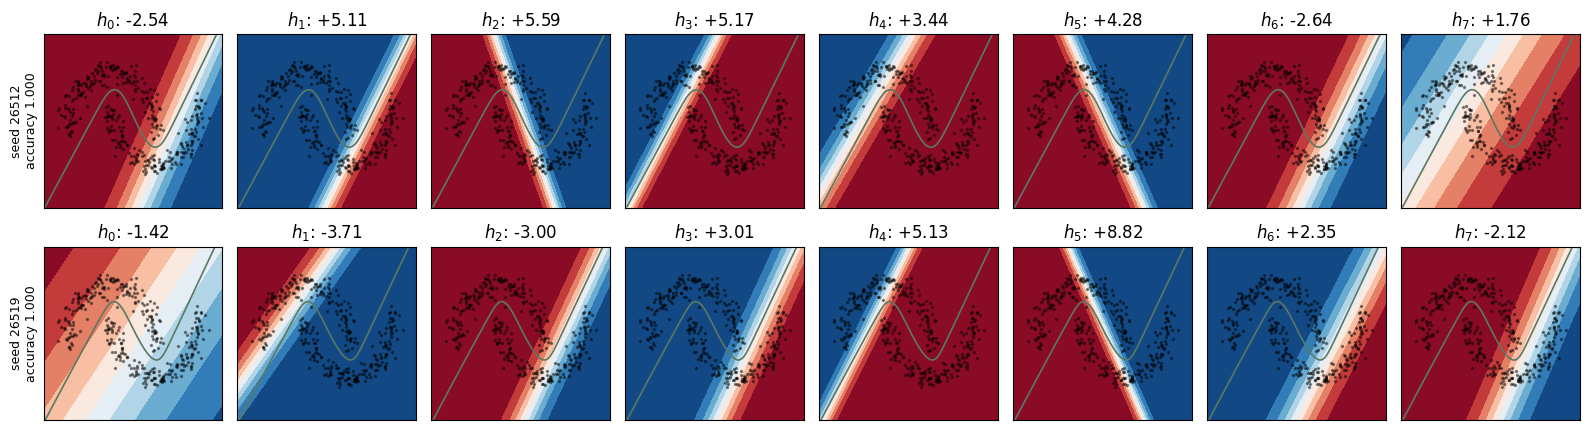

seed 26512: final loss 0.0020, accuracy 1.000, sorted output weights [-2.64 -2.54  1.76  3.44  4.28  5.11  5.17  5.59]
seed 26519: final loss 0.0023, accuracy 1.000, sorted output weights [-3.71 -3.   -2.12 -1.42  2.35  3.01  5.13  8.82]


In [9]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
rows = []
for row, seed in enumerate([SEED, SEED + 7]):
    fitted, losses_s, _ = train(seed=seed)
    accuracy = accuracy_of(fitted)
    draw_hidden_units(fitted, axes[row], compact=True)
    axes[row, 0].set_ylabel(f'seed {seed}\naccuracy {accuracy:.3f}', fontsize=9)
    rows.append((seed, losses_s[-1], accuracy, np.sort(fitted['w2'].ravel())))
plt.tight_layout(); plt.show()
for seed, final_loss, accuracy, weights in rows:
    print(f'seed {seed}: final loss {final_loss:.4f}, accuracy {accuracy:.3f}, '
          f'sorted output weights {np.round(weights, 2)}')
assert all(accuracy == 1.0 for _, _, accuracy, _ in rows)

Both seeds reach training accuracy 1.000, with final losses 0.0020 and
0.0023, and their green boundaries are nearly the same curve. Their hidden
units are different functions. The first run uses two negative output
weights and its largest is $+5.59$; the second uses four negative weights and
its largest is $+8.82$. Unit by unit the steps sit at different angles and
offsets, and the same index plays an unrelated role in the two rows (for
example, $h_0$ is a sharp step with weight $-2.54$ in the first run and a soft
ramp with weight $-1.42$ in the second). The decision rule is pinned down by
the data much more tightly than the representation that produces it.

## 9. Random boundaries before training

Each panel uses randomly initialized parameters; the labels were not used
to choose them. The top row has width 2, the bottom row width 32, six
draws each. The panel titles report each random rule's training accuracy.
Look at how curved the boundaries are and whether any of them follows the
moons.

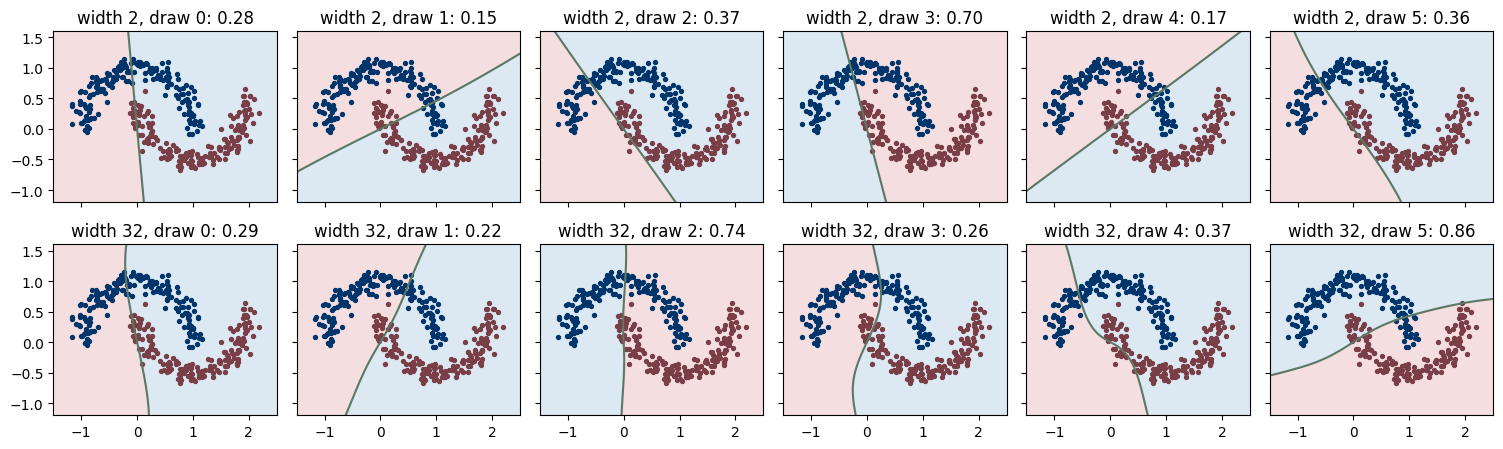

,0,1,2,3,4,5
width,,,,,,
2,0.275,0.147,0.367,0.697,0.167,0.364
32,0.286,0.219,0.739,0.258,0.372,0.856


In [10]:
fig, axes = plt.subplots(2, 6, figsize=(15, 4.6), sharex=True, sharey=True)
random_accuracy = {}
for row, width in enumerate([2, 32]):
    for col in range(6):
        random_params = initialize(width, seed=1000 * width + col)
        accuracy = accuracy_of(random_params)
        random_accuracy[(width, col)] = accuracy
        draw(axes[row, col], forward(random_params, grid)[2], title=f'width {width}, draw {col}: {accuracy:.2f}')
        axes[row, col].set(xlabel='', ylabel='')
plt.tight_layout(); plt.show()
random_table = pd.Series(random_accuracy).unstack().round(3)
random_table.index.name = 'width'
display(random_table)
assert max(random_accuracy.values()) < 0.9

Random parameters give random rules. The twelve accuracies range from 0.147
to 0.856; values below 0.5 mean the rule mostly assigns the classes the
wrong way round, and flipping its sign would score one minus that number.
Either way, the labels played no part. The width-two draws look almost like straight lines. This is
common at this initialization scale: with zero biases and modest hidden
scores, $\tanh(z)\approx z$, so the score is approximately
$s(x)\approx (w_2^\top W_1)x$. A width-two tanh network can also make a
nonlinear boundary; these six draws do not describe its full function class.
Some width-thirty-two draws curve visibly (draws 3 and 4), and draw 5 reaches
0.856 with a gentle curve, still below the straight line of Section 1. None
follows the moons. A large function class contains the separating curve;
training is what finds it.

## Verify the implementation with PyTorch

The finite-difference table checks five coordinates. PyTorch's autograd
gives an independent check of **every** coordinate. The next cell rebuilds
the same network from `torch` tensors in float64 that require gradients,
copies in the NumPy initialization, calls `backward()` on the same mean
cross-entropy, and compares all four gradient blocks with
`loss_and_gradients` at relative tolerance $10^{-6}$. It then runs 800 updates
of `torch.optim.SGD` at $\eta=3$ from the same start and compares the whole
loss curve with the NumPy run from Section 4. Look for the largest
discrepancies printed at the end.

In [11]:
import torch

X_t = torch.tensor(X, dtype=torch.float64)
y_t = torch.tensor(y, dtype=torch.float64)

def torch_loss(tparams):
    H_t = torch.tanh(X_t @ tparams['W1'] + tparams['b1'])
    s_t = (H_t @ tparams['w2'] + tparams['b2']).ravel()
    return torch.nn.functional.binary_cross_entropy_with_logits(s_t, y_t)

# 1. Gradients at the width-8 initialization.
start = initialize(width=8)
tparams = {k: torch.tensor(v, dtype=torch.float64, requires_grad=True) for k, v in start.items()}
loss_t = torch_loss(tparams)
loss_t.backward()
loss_np, gradients_np = loss_and_gradients(start, X, y)
gradient_gap = {}
for name in start:
    autograd = tparams[name].grad.numpy()
    assert np.allclose(gradients_np[name], autograd, rtol=1e-6, atol=1e-12)
    gradient_gap[name] = np.max(np.abs(gradients_np[name] - autograd)) / np.max(np.abs(autograd))
assert abs(loss_np - loss_t.item()) < 1e-9

# 2. The same 800 gradient-descent updates with torch.optim.SGD.
tparams = {k: torch.tensor(v, dtype=torch.float64, requires_grad=True) for k, v in start.items()}
optimizer = torch.optim.SGD(tparams.values(), lr=3.0)
torch_losses = []
for t in range(801):
    optimizer.zero_grad()
    objective = torch_loss(tparams)
    torch_losses.append(objective.item())
    if t == 800:
        break
    objective.backward()
    optimizer.step()
torch_losses = np.array(torch_losses)
assert np.allclose(torch_losses, losses, rtol=1e-6, atol=1e-9)

print(f'loss at initialization: NumPy {loss_np:.10f}, PyTorch {loss_t.item():.10f}')
for name, gap in gradient_gap.items():
    print(f'max |NumPy - autograd| / max |autograd| for {name:2s}: {gap:.1e}')
print(f'largest loss-curve gap over 800 updates: {np.max(np.abs(torch_losses - losses)):.1e}')
print(f'final loss: NumPy {losses[-1]:.6f}, PyTorch {torch_losses[-1]:.6f}')

loss at initialization: NumPy 0.6101125108, PyTorch 0.6101125108
max |NumPy - autograd| / max |autograd| for W1: 3.1e-16
max |NumPy - autograd| / max |autograd| for b1: 1.2e-15
max |NumPy - autograd| / max |autograd| for w2: 4.4e-16
max |NumPy - autograd| / max |autograd| for b2: 4.9e-16
largest loss-curve gap over 800 updates: 1.9e-12
final loss: NumPy 0.002029, PyTorch 0.002029


Autograd and the hand-written backward pass agree on all $4m+1=33$
gradient coordinates to about $10^{-15}$ relative error, which is float64
rounding; the asserts used tolerance $10^{-6}$. The losses at initialization
agree to ten digits (0.6101125108). Over 800 updates of `torch.optim.SGD` the
two loss curves never differ by more than $2\times10^{-12}$, and both end at
loss 0.002029. So the NumPy update $\theta\leftarrow\theta-\eta\nabla L$ is
exactly what PyTorch's plain SGD does, and the backpropagation formulas of
Section 3 are what autograd computes.

## Summary

Width and the activation function decide the **function class**: a
width-one tanh network has a straight decision boundary when it has one,
while additional units can combine to make curved boundaries. Replacing
tanh with the identity collapses any width to logistic regression. The
learning rate, the number of updates, and the random seed affect the
**training path** through that class: too large a rate fails to settle,
too few updates stop early, and different seeds can reach different useful
representations.

## Try It

For each change, write down your prediction before running the cell.

1. **Find the edge of stability.** Rerun Section 7 with $\eta\in\{5,10,15,20\}$.
   At which rate does the loss first spike above its starting value 0.610
   during the first 100 updates? Does that run still reach accuracy 1.0 by
   update 400?
2. **Swap tanh for ReLU.** Replace `np.tanh` in `forward` by
   `lambda z: np.maximum(z, 0)` and $1-H^2$ in `loss_and_gradients` by
   `(Z > 0)`. Rerun the finite-difference check first. Then predict: is a
   width-two ReLU boundary still nearly straight, or does it bend at a kink?
3. **Width one, many seeds.** Train width 1 with ten different seeds. Can any
   of them beat the 0.883 accuracy of logistic regression by much? Explain
   your answer from the fact that its boundary is a line.
4. **Fewer updates.** Train width 32 for only 20 updates and for 100 updates.
   Which category does "number of updates" belong to, function class or
   training path? Compare with the width-2 run at 800 updates.
5. **Initialization scale.** Change the first-layer scale from 0.65 to 3 and
   redraw Section 9. With larger hidden scores, $\tanh$ saturates and stops
   looking linear. Predict whether the width-two random boundaries now bend.
6. **Noisier moons and held-out data.** Generate data with noise 0.25 and a
   separate test set from `two_moons(seed=SEED + 1)`. Train widths 4 and 32.
   Training accuracy will fall below 1.0; which width do you expect to have
   the larger gap between training and test accuracy?